In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fitsio
import healpy as hp
from scipy.interpolate import interp1d
from scipy.constants import pi, h, c, e, m_e, k, epsilon_0, physical_constants
from scipy.special import wofz
import sys


In [2]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'cmr10' 
plt.rcParams['font.size'] = 15
plt.rc('axes', unicode_minus=False)


# Load the ULSA Sky Map

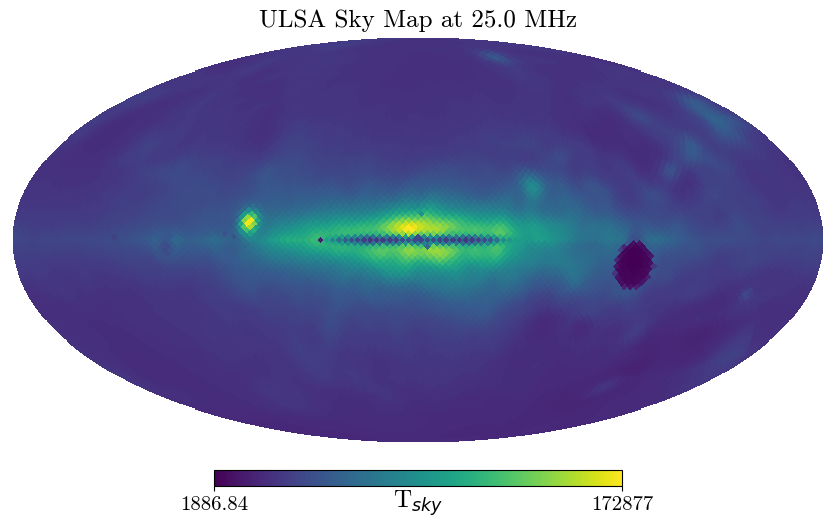

In [ ]:
# Load the ULSA sky map

ulsa_map_path = ### Path to ULSA sky map file ###
header        = fitsio.read_header(ulsa_map_path)
ulsa_maps     = fitsio.FITS(ulsa_map_path, "r")[0].read()
nside         = hp.get_nside(ulsa_maps[0])
npix          = hp.nside2npix(nside)

fstart = header['freq_start'] * 1e6  # Hz
fend   = header['freq_end']   * 1e6  # Hz
fstep  = header['freq_step']  * 1e6  # Hz

original_freqs = np.arange(fstart, fend + fstep, fstep)

freq = 25 * 1e6 # Hz
freq_idx = np.where(original_freqs == freq)[0][0]
hp.mollview(ulsa_maps[freq_idx], title = f"ULSA Sky Map at {freq/1e6} MHz", unit = r"T$_{sky}$")
plt.show()


# Identify Frequencies Where CRRLs are Centered

In [62]:
# Define parameters

# Radiative Transfer
f_back = 0.2
tau_nonLTE_gc = 1e-3 
tau_nonLTE_plane = 5e-4
tau_nonLTE_away = 1e-4

# Radiation Broadening 
T0_gc    = 2000
T0_plane = 2000
T0_away  = 1e3

# Collisional Broadening
Ne_gc = 0.02
Ne_p = 0.02 
Ne_a = 0.02
Te = 100 

# Doppler Broadening
T_gas = 100 
V_turb = 20 
V_rot_gc = 0
V_rot_plane = 0 
V_rot_away = 0 
V_vel = 0

# Sky mask ranges
b_max_deg = 3.0
l_max_deg = 40.0
gal_range = 10

In [63]:
def rydberg(M):
    numerator = 2 * pi**2 * m_e * e**4
    denom = (4 * pi * epsilon_0)**2 * c * h**3
    reduced_mass_factor = M / (M + m_e)
    return (numerator / denom) * reduced_mass_factor

m_H = physical_constants["proton mass"][0]
R_H = rydberg(m_H)
m_C = 12 * physical_constants["atomic mass constant"][0]
R_C = rydberg(m_C)

def rydberg_freq(n1, n2, Z=1, R=R_H):
    return c * R * Z**2 * (1 / n1**2 - 1 / n2**2)

def rrl_freqs(freq_range=(1e6, 50e6), n_min=100, n_max=2000, Z=1, R=R_H):
    freqs = []
    n_transition = []

    for n in range(n_min, n_max):
        f = rydberg_freq(n, n + 1, Z=Z, R=R)
        if freq_range[0] <= f <= freq_range[1]:
            freqs.append(f)
            n_transition.append(n)

    return np.array(n_transition), np.array(freqs)

In [64]:
freq_min_hz = 10 * 1e6
freq_max_hz = 50 * 1e6

n_vals, crrl_freq = rrl_freqs((freq_min_hz, freq_max_hz), Z=1, R=R_C)

In [65]:
print(f"Between {freq_min_hz/1e6} and {freq_max_hz/1e6} MHz, there are {n_vals.size} CRRLs:")
print(f"\tFirst C{n_vals[-1]}α: {crrl_freq[-1]/1e6:.3f} MHz")
print(f"\tLast C{n_vals[0]}α: {crrl_freq[0]/1e6:.3f} MHz")

Between 10.0 and 50.0 MHz, there are 361 CRRLs:
	First C869α: 10.009 MHz
	Last C509α: 49.745 MHz


# Create the RRL Line Profile

### 1) Doppler Broadening

In [66]:
# Doppler Broadening
def compute_dopp_fwhm(
    crrl_freq_hz,
    T_gas_K=100,               # gas temperature K, 50-100K for CNM
    V_turb_kms=20,             # turbulent velocity km/s
    V_rot_kms=0,               # galactic rotation velocity towards galactic plane km/s
    V_vel_kms=0,               # luSEE (Moon) orbital velocity projection km/s
    M_amu=12.0                 # atomic mass for carbon (amu)
):
   
    # Physical constants
    k_B = 1.380649e-23      # Boltzmann constant, J/K
    m_p = 1.6726e-27        # mass of proton, kg
    c = 3.0e8               # speed of light, m/s

    # velocities in m/s
    V_gas = np.sqrt(2 * k_B * T_gas_K / (M_amu * m_p))
    V_turb = V_turb_kms * 1e3
    V_rot = V_rot_kms * 1e3
    V_vel = V_vel_kms * 1e3

    # FWHM
    v2 = 4*np.log(2)*(V_gas**2 + V_turb**2) + V_rot**2 + V_vel**2
    fwhm_hz = (crrl_freq_hz / c) * np.sqrt(v2)
    
    return fwhm_hz

In [67]:
dopp_gc      = np.array([compute_dopp_fwhm(f, V_rot_kms=V_rot_gc,      V_vel_kms=V_vel) for f in crrl_freq])
dopp_towards = np.array([compute_dopp_fwhm(f, V_rot_kms=V_rot_plane,   V_vel_kms=V_vel) for f in crrl_freq])
dopp_away    = np.array([compute_dopp_fwhm(f, V_rot_kms=V_rot_away,    V_vel_kms=V_vel) for f in crrl_freq])

### 2) Radiation Broadening

In [68]:
# Radiation Broadening
def compute_rad_fwhm(n_vals, T_0): 
    n_vals = np.asarray(n_vals)
    return 6.096e-17 * T_0 * n_vals**5.8 # Hz

In [69]:
rad_gc      = compute_rad_fwhm(n_vals, T_0=T0_gc)
rad_towards = compute_rad_fwhm(n_vals, T_0=T0_plane)
rad_away    = compute_rad_fwhm(n_vals, T_0=T0_away)

### 3) Collisional Broadening

In [70]:
# Table of a(T_e) and gamma_c(T_e) from Table 3 (Salgado et al)
Te_vals = np.array([50, 60, 70, 80, 90, 100])  # Kelvin
a_vals =  np.array([-10.27, -10.19, -10.12, -10.06, -10.01, -9.961])
gamma_vals = np.array([5.369, 5.354, 5.341, 5.329, 5.318, 5.308])

def compute_col_fwhm(n_vals, Te, Ne, dn=1):
    
    # Interpolate coefficients a and gamma_c
    a_interp = np.interp(Te, Te_vals, a_vals)
    gamma_interp = np.interp(Te, Te_vals, gamma_vals)

    # Average over n and n + dn 
    term_n = n_vals**gamma_interp
    term_np = (n_vals + dn)**gamma_interp
    C_sum = 10**a_interp * (term_n + term_np) / 2

    col_fwhm = (1 / np.pi) * Ne * C_sum  # Hz

    return col_fwhm

In [71]:
col_gc      = compute_col_fwhm(n_vals, Te, Ne_gc)
col_towards = compute_col_fwhm(n_vals, Te, Ne_p)
col_away    = compute_col_fwhm(n_vals, Te, Ne_a)

In [72]:
lorentz_gc      = col_gc + rad_gc
lorentz_towards = col_towards + rad_towards
lorentz_away    = col_away + rad_away

## Create Voigt Profile

In [73]:
def voigt_fwhm(fwhm_gauss, fwhm_lorentz):
    return 0.5346 * fwhm_lorentz + np.sqrt(0.2166 * fwhm_lorentz**2 + fwhm_gauss**2)

def compute_voigt_profile(x, fwhm_gauss, fwhm_lorentz): # area is normalized
    sigma = fwhm_gauss / (2 * np.sqrt(2 * np.log(2)))   # Convert FWHM to std dev
    gamma = fwhm_lorentz / 2                            # Convert FWHM to HWHM
    
    z = (x + 1j * gamma) / (sigma * np.sqrt(2))
    return np.real(wofz(z)) / (sigma * np.sqrt(2 * np.pi))

def voigt_peak_normalized(x_hz, fwhm_gauss_hz, fwhm_lorentz_hz):
    sigma = fwhm_gauss_hz / (2.0*np.sqrt(2.0*np.log(2.0)))
    gamma = fwhm_lorentz_hz / 2.0

    phi_area = compute_voigt_profile(x_hz, fwhm_gauss_hz, fwhm_lorentz_hz)

    z0 = (0.0 + 1j*gamma) / (sigma*np.sqrt(2.0))
    peak_area = np.real(wofz(z0)) / (sigma*np.sqrt(2.0*np.pi))  # 1/Hz
    phi_peak = phi_area / peak_area
    Aphi_hz = 1.0 / peak_area
    return phi_peak, Aphi_hz

### a) Calculate the Background Sky Temperature for Each of the 3 Sky Regions

In [74]:
# Linearly interpolate maps to identified frequencies
interpolator_func = interp1d(original_freqs, ulsa_maps, axis=0, kind='linear', bounds_error=True) 
interpolated_ulsa_maps = interpolator_func(crrl_freq) 

In [75]:
# Params to define sky regions
b_max_deg  = 3.0
l_max_deg  = 40.0
gal_range  = 10.0


In [76]:
# Calculate lon and lat coordinates for sky map
theta, phi   = hp.pix2ang(nside, np.arange(npix))
lat_deg      = np.degrees(0.5*np.pi - theta)
lon_deg      = np.degrees(phi)
lon_centered = ((lon_deg + 180.0) % 360.0) - 180.0

In [77]:
def T_bg(freq_hz, interp_freqs, interpolated_ulsa_maps, sky_mask):
    # Return mean of the masked ULSA sky map at a given frequency
    idx = np.argmin(np.abs(interp_freqs - freq_hz))
    slice_freq = interpolated_ulsa_maps[idx]
    return np.mean(slice_freq[sky_mask])


In [78]:
# Define sky masks
gc_mask              = (np.abs(lat_deg) <= b_max_deg) & (np.abs(lon_centered) <= l_max_deg)
gp_mask              = (np.abs(lat_deg) <= gal_range) & ~gc_mask
away_mask            = np.abs(lat_deg) > gal_range

T_bgs_gc    = np.array([T_bg(f, crrl_freq, interpolated_ulsa_maps, gc_mask)    for f in crrl_freq])
T_bgs_gp    = np.array([T_bg(f, crrl_freq, interpolated_ulsa_maps, gp_mask)    for f in crrl_freq])
T_bgs_away  = np.array([T_bg(f, crrl_freq, interpolated_ulsa_maps, away_mask)  for f in crrl_freq])


### b) Plot the Spectra

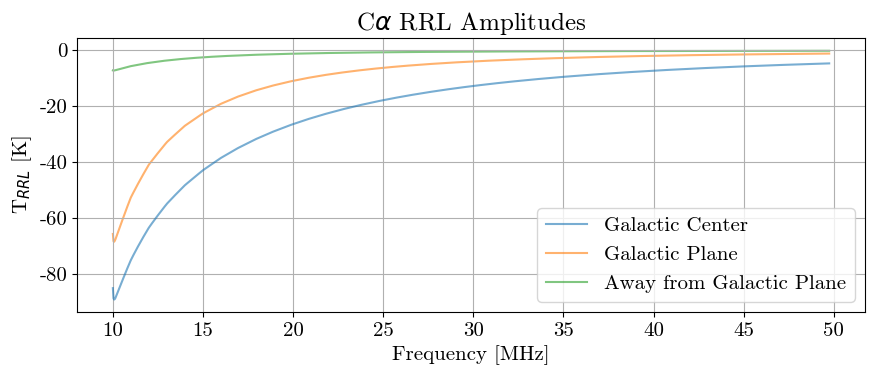

In [79]:
### SKY MODEL 3

tau_values = np.array([1e-3, 5e-4, 1e-4]) 

def deltaT_simple(tau_nonLTE, T_cont, f_back=0.2):
    return -tau_nonLTE * (f_back * T_cont)

def build_spec(tau_nonLTE, sightline="plane"):
    spec = np.zeros_like(crrl_freq, dtype=float)
    for i in range(len(n_vals)):
        nu0   = crrl_freq[i]
        x_val = crrl_freq - nu0
        if sightline == "plane":
            v, _ = voigt_peak_normalized(x_val, dopp_towards[i], lorentz_towards[i])
            Tcont = float(T_bgs_gp[i])
        elif sightline == "gc":
            v, _ = voigt_peak_normalized(x_val, dopp_towards[i], lorentz_towards[i])
            Tcont = float(T_bgs_gc[i])
        else:
            v, _ = voigt_peak_normalized(x_val, dopp_away[i],  lorentz_away[i])
            Tcont = float(T_bgs_away[i])
        A0 = deltaT_simple(tau_nonLTE, Tcont, f_back=f_back)
        spec += A0 * v
    return spec

# --- plot: galactic center ---
plt.figure(figsize=(9,4))
tau_nonLTE = tau_values[0]
spec_gc = build_spec(tau_nonLTE, sightline="gc")
plt.plot(crrl_freq/1e6, spec_gc, alpha=0.6,
            label="Galactic Center", zorder=2)

# --- plot: towards plane ---
tau_nonLTE = tau_values[1]
spec_plane = build_spec(tau_nonLTE, sightline="plane")
plt.plot(crrl_freq/1e6, spec_plane, alpha=0.6,
            label="Galactic Plane", zorder=1)

# --- plot: away from plane ---
tau_nonLTE = tau_values[2]
spec_away = build_spec(tau_nonLTE, sightline="away")
plt.plot(crrl_freq/1e6, spec_away, alpha=0.6,
            label=f"Away from Galactic Plane", zorder=0)

plt.xlabel("Frequency [MHz]")
plt.ylabel(r"T$_{RRL}$ [K]")
#plt.title(r"Undiluted C$\alpha$ RRL Spectrum")
plt.title(r"C$\alpha$ RRL Amplitudes")
plt.grid(True); plt.legend()
plt.tight_layout()

plt.show()


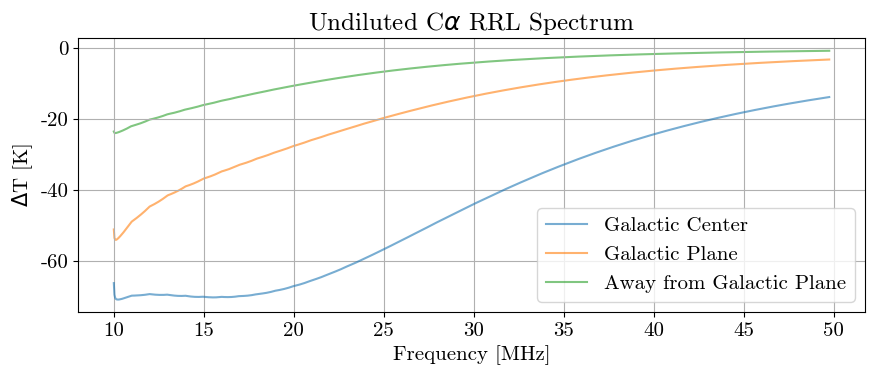

In [80]:
### SKY MODEL 6

tau_values = np.array([20, 10, 5]) 

def deltaT_simple(tau_nonLTE, T_cont, f_back=0.2):
    return -tau_nonLTE * (f_back * T_cont)

def build_spec(tau_nonLTE, sightline="plane"):
    spec = np.zeros_like(crrl_freq, dtype=float)
    for i in range(len(n_vals)):
        nu0   = crrl_freq[i]
        x_val = crrl_freq - nu0
        if sightline == "plane":
            v = compute_voigt_profile(x_val, dopp_towards[i], lorentz_towards[i])
            Tcont = float(T_bgs_gp[i])
        elif sightline == "gc":
            v = compute_voigt_profile(x_val, dopp_towards[i], lorentz_towards[i])
            Tcont = float(T_bgs_gc[i])
        else:
            v = compute_voigt_profile(x_val, dopp_away[i],  lorentz_away[i])
            Tcont = float(T_bgs_away[i])
        A0 = deltaT_simple(tau_nonLTE, Tcont, f_back=f_back)
        spec += A0 * v
    return spec

# --- plot: galactic center ---
plt.figure(figsize=(9,4))
tau_nonLTE = tau_values[0]
spec_gc = build_spec(tau_nonLTE, sightline="gc")
plt.plot(crrl_freq/1e6, spec_gc, alpha=0.6,
            label="Galactic Center", zorder=2)

# --- plot: towards plane ---
tau_nonLTE = tau_values[1]
spec_plane = build_spec(tau_nonLTE, sightline="plane")
plt.plot(crrl_freq/1e6, spec_plane, alpha=0.6,
            label="Galactic Plane", zorder=1)

# --- plot: away from plane ---
tau_nonLTE = tau_values[2]
spec_away = build_spec(tau_nonLTE, sightline="away")
plt.plot(crrl_freq/1e6, spec_away, alpha=0.6,
            label=f"Away from Galactic Plane", zorder=0)

plt.xlabel("Frequency [MHz]")
plt.ylabel(r"$\Delta$T [K]")
plt.title(r"Undiluted C$\alpha$ RRL Spectrum")
plt.grid(True); plt.legend()
plt.tight_layout()

plt.show()


### Reproduce Fig 1

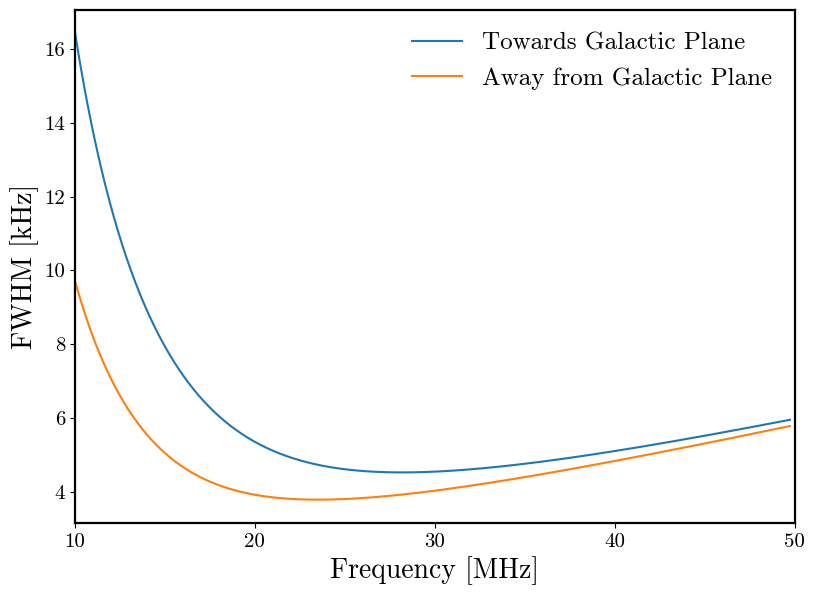

In [81]:
v_towards = []
v_away    = []

for i in range(len(n_vals)):
    nu0   = crrl_freq[i]
    x_val = crrl_freq - nu0
    v_towards.append(voigt_fwhm(dopp_towards[i], lorentz_towards[i]))
    v_away.append(voigt_fwhm(dopp_away[i], lorentz_away[i]))
    
v_towards = np.array(v_towards)
v_away    = np.array(v_away)

fig, ax = plt.subplots(figsize=(8.4, 6.2))

ax.plot(crrl_freq/1e6, v_towards / 1e3, label = "Towards Galactic Plane")
ax.plot(crrl_freq/1e6, v_away / 1e3, label = "Away from Galactic Plane")

ax.set_xlabel("Frequency [MHz]", color="black", fontsize=20)
ax.set_ylabel("FWHM [kHz]", color="black", fontsize=20)

ax.legend(fontsize=18, loc="best", frameon=False)
leg.get_frame().set_edgecolor("black")
leg.get_frame().set_linewidth(1.2)
leg.get_frame().set_facecolor("white")

# Choose clean MHz ticks within data range
tick_candidates = np.array([10, 20, 30, 40, 50, 60], dtype=float)
xticks = tick_candidates[(tick_candidates >= mhz.min()*0.99) & (tick_candidates <= mhz.max()*1.01)]
if xticks.size >= 2:
    ax.set_xticks(xticks)
    
ax.set_xlim([10, 50])

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.6)

plt.tight_layout()
plt.show()

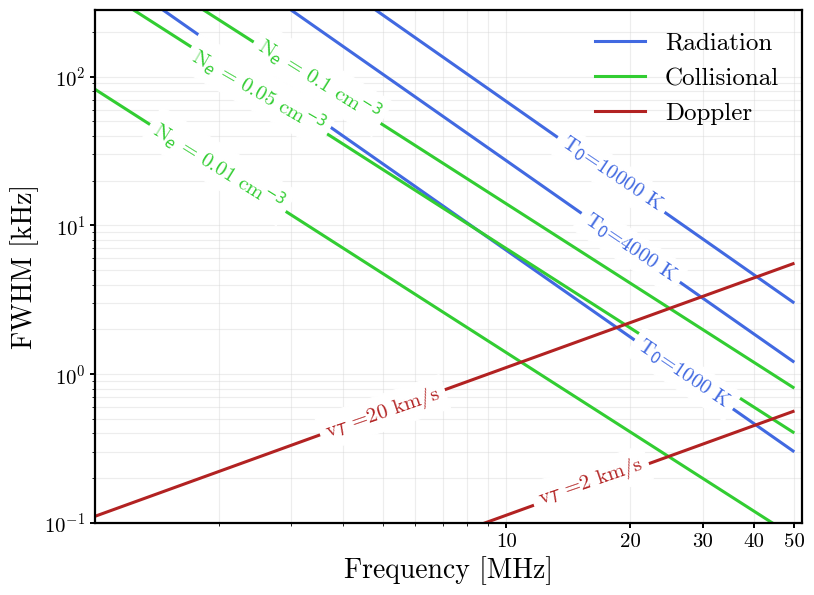

In [82]:
# --- PARAMETERS ---
T0_list   = [1000.0, 4000.0, 10000.0]    # K (radiation field at 100 MHz)
Ne_list   = [0.01, 0.05, 0.1]   # cm^-3 (electron density)
vturb_set = [2, 20]             # km/s (turbulent rms)

Te_e = 100.0   # K (electron temperature for collisional broadening)
Tgas = 100.0   # K (gas temperature for Doppler)

n_vals, crrl_freq = rrl_freqs((1e6, 50e6), Z=1, R=R_C)

# --- PLOT ---
fig, ax = plt.subplots(figsize=(8.4, 6.2))
legend_labels = {"Radiation": False, "Collisional": False, "Doppler": False}

# Radiation
for T0 in T0_list:
    lbl = "Radiation" if not legend_labels["Radiation"] else None
    yvals = compute_rad_fwhm(n_vals, T0) / 1e3  # kHz
    ax.loglog(crrl_freq/1e6, yvals, lw=2.2, color='royalblue', label=lbl)
    legend_labels["Radiation"] = True

# Collisional
for Ne in Ne_list:
    lbl = "Collisional" if not legend_labels["Collisional"] else None
    yvals = compute_col_fwhm(n_vals, Te_e, Ne) / 1e3  # kHz
    ax.loglog(crrl_freq/1e6, yvals, lw=2.2, color='limegreen', label=lbl)
    legend_labels["Collisional"] = True

# Doppler
for v in vturb_set:
    lbl = "Doppler" if not legend_labels["Doppler"] else None
    yvals = compute_dopp_fwhm(crrl_freq, T_gas_K=Tgas,
                         V_turb_kms=v, V_rot_kms=0, V_vel_kms=0) / 1e3  # kHz
    ax.loglog(crrl_freq/1e6, yvals, lw=2.2, color='firebrick', label=lbl)
    legend_labels["Doppler"] = True

# --- Manual label positions ---
manual_positions = [
    (r"T$_0$=1000 K",           'royalblue',  27,   1.0,  -34),
    (r"T$_0$=4000 K",           'royalblue',  20,   7,    -34),
    (r"T$_0$=10000 K",          'royalblue',  18.0, 22,   -34),
    (r"N$_e$ = 0.01 cm$^{-3}$", 'limegreen',  2.0,  25,   -32),
    (r"N$_e$ = 0.05 cm$^{-3}$", 'limegreen',  2.5,  80,   -30),
    (r"N$_e$ = 0.1 cm$^{-3}$",  'limegreen',  3.5,  95.0, -32),
    (r"v$_{T}$ =2 km/s",        'firebrick',  16,   0.19, 19),
    (r"v$_{T}$ =20 km/s",       'firebrick',  5,    0.55, 19),
]

# Limits (room on right for labels)
x_max_label = max(x for _, _, x, _,_ in manual_positions)
mhz = crrl_freq / 1e6
x_min, x_max = mhz.min(), mhz.max()
ax.set_xlim(x_min, max(x_max*1.05, x_max_label*1.02))

for text, color, x, y, rotation in manual_positions:
    ax.text(x, y, text, color=color, fontsize=15, fontweight="bold",
            ha="center", va="center", rotation=rotation, backgroundcolor='white')

# --- Formatting ---
ax.set_xlabel("Frequency [MHz]", color="black", fontsize=20)
ax.set_ylabel("FWHM [kHz]", color="black", fontsize=20)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.6)

ax.tick_params(axis='both', colors="black", width=1.4, labelsize=15)
ax.grid(True, which="both", alpha=0.4, linewidth=0.8, color="lightgrey")

# Legend
leg = ax.legend(fontsize=18, loc="best", frameon=False)
leg.get_frame().set_edgecolor("black")
leg.get_frame().set_linewidth(1.2)
leg.get_frame().set_facecolor("white")

# --- Make X tick labels show real MHz numbers on a log axis ---
from matplotlib.ticker import ScalarFormatter
import numpy as np

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.ticklabel_format(axis='x', style='plain')  # no scientific notation

# Choose clean MHz ticks within data range
tick_candidates = np.array([10, 20, 30, 40, 50, 60], dtype=float)
xticks = tick_candidates[(tick_candidates >= mhz.min()*0.99) & (tick_candidates <= mhz.max()*1.01)]
if xticks.size >= 2:
    ax.set_xticks(xticks)

# Set y-limits once (log scale)
ax.set_ylim(0.1, 280)

plt.tight_layout()
plt.show()
